In [1]:
import pandas as pd
from load import MergedExposureDataset, MonitorsDataset, ExposureDataset
import matplotlib.pyplot as plt
import geopandas as gpd
import textwrap
from config import *

sdf = gpd.read_file(STATESHAPEFILE_PATH)
sdf = sdf[sdf['STUSPS'].isin(['AZ', 'CA', 'CO', 'ID', 'MT', 'NV', 'NM', 'OR', 'UT', 'WA','WY'])]

INFO:load:Loading MonitorsDataset from path data/annual_conc_by_monitor_2024.csv
INFO:load:Monitors CRS: ['NAD83' 'WGS84']
INFO:load:Loading ShapefileDataset from path ../coexposure/data/WesternUSCensusTract/CensusTract2020_WesternUS.shp
INFO:load:Shapefile CRS: PROJCS["USA_Contiguous_Albers_Equal_Area_Conic",GEOGCS["NAD83",DATUM["North_American_Datum_1983",SPHEROID["GRS 1980",6378137,298.257222101,AUTHORITY["EPSG","7019"]],AUTHORITY["EPSG","6269"]],PRIMEM["Greenwich",0,AUTHORITY["EPSG","8901"]],UNIT["degree",0.0174532925199433,AUTHORITY["EPSG","9122"]],AUTHORITY["EPSG","4269"]],PROJECTION["Albers_Conic_Equal_Area"],PARAMETER["latitude_of_center",37.5],PARAMETER["longitude_of_center",-96],PARAMETER["standard_parallel_1",29.5],PARAMETER["standard_parallel_2",45.5],PARAMETER["false_easting",0],PARAMETER["false_northing",0],UNIT["metre",1,AUTHORITY["EPSG","9001"]],AXIS["Easting",EAST],AXIS["Northing",NORTH],AUTHORITY["ESRI","102003"]]


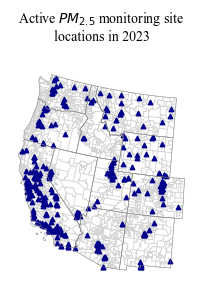

In [2]:
MonitorsDataset().plotMonitors()

In [3]:
df = MergedExposureDataset(reload=True).getMergedExposure()

INFO:load:Loading SmokePMDataset from path smoke_pm/area_weighted_smoke_pm_corr.parquet


Reloading data and ignoring cache for cache/merged_df.pkl.


INFO:load:Data loaded from cache.
INFO:load:Data summary:        avg_yrly_smoke_pm_gt_5  avg_yrly_smoke_pm
count            18108.000000       18108.000000
mean                 8.954536           0.535156
std                  5.064510           0.378835
min                  2.066667           0.105642
25%                  5.533333           0.275517
50%                  7.466667           0.402458
75%                 10.933333           0.710694
max                 37.133333           3.180479
INFO:load:Loading TotalPM25Dataset from path ../coexposure/outputs/total_total_pm25_pollution.parquet


Loading cached data from cache/smoke_pm_df.pkl


INFO:load:Data loaded from cache.
INFO:load:Data summary:        avg_yrly_pm25_gt_5  avg_yrly_pm25
count        18010.000000   18010.000000
mean           274.178223       8.961714
std             82.111820       3.122284
min             26.333333       2.187771
25%            221.733333       6.698694
50%            301.933333       8.336958
75%            345.200000      11.012399
max            359.666667      20.074779
INFO:load:Loading TotalPM25Dataset from path ../coexposure/outputs/total_total_pm25_pollution.parquet


Loading cached data from cache/total_pm25_df.pkl


... (5 outputs left out)

Loading cached data from cache/shapefile_df.pkl


INFO:load:Monitors CRS: ['NAD83' 'WGS84']
INFO:load:Loading ShapefileDataset from path ../coexposure/data/WesternUSCensusTract/CensusTract2020_WesternUS.shp
INFO:load:Shapefile CRS: PROJCS["USA_Contiguous_Albers_Equal_Area_Conic",GEOGCS["NAD83",DATUM["North_American_Datum_1983",SPHEROID["GRS 1980",6378137,298.257222101,AUTHORITY["EPSG","7019"]],AUTHORITY["EPSG","6269"]],PRIMEM["Greenwich",0,AUTHORITY["EPSG","8901"]],UNIT["degree",0.0174532925199433,AUTHORITY["EPSG","9122"]],AUTHORITY["EPSG","4269"]],PROJECTION["Albers_Conic_Equal_Area"],PARAMETER["latitude_of_center",37.5],PARAMETER["longitude_of_center",-96],PARAMETER["standard_parallel_1",29.5],PARAMETER["standard_parallel_2",45.5],PARAMETER["false_easting",0],PARAMETER["false_northing",0],UNIT["metre",1,AUTHORITY["EPSG","9001"]],AXIS["Easting",EAST],AXIS["Northing",NORTH],AUTHORITY["ESRI","102003"]]
INFO:load:Number of monitors: 289
INFO:load:Number of locations: 391


Cache not found for cache/monitors_df.pkl. Generating data...


INFO:load:Number of unique entries after exposure join: 18108
INFO:load:Number of unique entries after urban/rural join: 18108
INFO:load:Number of locations with monitors: 288
INFO:load:Number of unique entries after monitors join: 18108


In [4]:
gdf = gpd.GeoDataFrame(df, geometry=df.geometry, crs="ESRI:102003")

In [5]:
sdf = sdf.to_crs(gdf.crs)

In [6]:
gdf["POP_SQMI"] = gdf["POPULATION"] / gdf["SQMI"]

In [7]:
days_cmap = "magma_r"
def draw_A(ax):
    cmap = plt.cm.magma_r
    vmax = 15
    norm = plt.Normalize(vmin=0, vmax=vmax)  
    sm = plt.cm.ScalarMappable(cmap=cmap, norm=norm)
    sm.set_array([])

    x = "avg_yrly_pm25_gt_35"

    gdf.plot(
        column=x, 
        vmax=vmax,
        ax=ax, 
        legend=False, 
        linewidth=0, 
        cmap=cmap,
        missing_kwds={"color": "lightgrey"}, 
        norm = norm
        )
    sdf.boundary.plot(ax=ax, linewidth=0.3, color="white")
    wrapped_title = textwrap.fill(r"Average number of high air pollution days ($PM_{2.5}>35μg/m^3$)", 40) 
    ax.set_title(wrapped_title, fontsize=10)
    ax.set_axis_off()

    # Add colorbar
    cbar = plt.colorbar(sm, ax=ax)

    plt.tight_layout()
    #plt.savefig("figures/centract_hotspots_wc_241028.png", dpi=300, bbox_inches='tight')
    ax.annotate("(A)", xy=(0.02, 0.02), xycoords="axes fraction", fontsize=12, fontweight="bold")

def draw_B(ax):
    norm = None
    x = "avg_yrly_pm25_gt_5"
    gdf.plot(
        column=x, 
        # vmax=5000,
        # vmin=500,
        ax=ax, 
        legend=True, 
        linewidth=0, 
        cmap=days_cmap, 
        missing_kwds={"color": "lightgrey"}, norm = norm
        )
    sdf.boundary.plot(ax=ax, linewidth=0.3, color="white")
    wrapped_title = textwrap.fill(r"Average number of air pollution days ($PM_{2.5}>5μg/m^3$)", 40) # " "
    ax.set_title(wrapped_title, fontsize=10)
    ax.set_axis_off()

    plt.tight_layout()
    ax.annotate("(B)", xy=(0.02, 0.02), xycoords="axes fraction", fontsize=12, fontweight="bold")

    #plt.savefig("figures/avg_yrly_pm25_gt_5.png", dpi=300, bbox_inches='tight')
    #plt.show()

def draw_C(ax):
    norm = None
    x = "avg_yrly_smoke_pm_gt_5"
    gdf.plot(
        column=x, 
        # vmax=5000,
        # vmin=500,
        ax=ax, 
        legend=True, 
        linewidth=0, 
        cmap=days_cmap, 
        missing_kwds={"color": "lightgrey"}, norm = norm
        )
    sdf.boundary.plot(ax=ax, linewidth=0.3, color="white")
    wrapped_title = textwrap.fill(r"Average number of wildfire smoke days per year", 40) # " "
    ax.set_title(wrapped_title, fontsize=10)
    ax.set_axis_off()

    plt.tight_layout()
    ax.annotate("(B)", xy=(0.02, 0.02), xycoords="axes fraction", fontsize=12, fontweight="bold")
    #plt.savefig("figures/avg_yrly_smoke_pm_gt_5.png", dpi=300, bbox_inches='tight')

In [8]:
conc_cmap = "inferno_r"
def draw_D(ax):
    # vmax = data[x].max()
    # vmin = data[x].min()
    # vmax = 0.7 * vmax
    cmap = conc_cmap
    # sm = plt.cm.ScalarMappable(cmap=cmap, norm=plt.Normalize(vmin=vmin, vmax=vmax))
    # sm.set_array([])
    x = "avg_yrly_pm25"
    gdf.plot(
        column=x, 
        ax=ax, 
        legend=True, 
        #aspect='equal',
        # vmax=5000,
        # vmin=500,
        linewidth=0, 
        cmap=cmap, 
        missing_kwds={"color": "lightgrey"},
        )
    sdf.boundary.plot(ax=ax, linewidth=0.3, color='white')

    #title_text = "Total days of air pollution exposure ("+ titles[x]+ ") from 2006 to 2020"
    title_text = r"Average annual concentration of total ambient $PM_{2.5}$ ($μg/m^3$)"
    wrapped_title = textwrap.fill(title_text, 40)
    ax.set_title(wrapped_title, fontsize=10)
    ax.set_axis_off()
    plt.axis('equal')
    plt.tight_layout()
    ax.annotate("(C)", xy=(0.02, 0.02), xycoords="axes fraction", fontsize=12, fontweight="bold")
    #plt.savefig("figures/centract_hotspots_wc_mean_pm25_air"+x+".png", dpi=300, bbox_inches='tight')
    #plt.show()

def draw_E(ax):
    norm = None
    x = "avg_yrly_smoke_pm"
    gdf.plot(
        column=x, 
        ax=ax, 
        legend=True, 
        linewidth=0, 
        cmap=conc_cmap, 
        missing_kwds={"color": "lightgrey"}, norm = norm
        )
    sdf.boundary.plot(ax=ax, linewidth=0.3, color="white")
    wrapped_title = textwrap.fill(r"Average annual concentration of wildfire smoke $PM_{2.5}$ ($μg/m^3$)", 40) 
    ax.set_title(wrapped_title, fontsize=10)
    ax.set_axis_off()

    plt.tight_layout()
    #plt.savefig("figures/centract_hotspots_wc_241028.png", dpi=300, bbox_inches='tight')
    ax.annotate("(D)", xy=(0.02, 0.02), xycoords="axes fraction", fontsize=12, fontweight="bold")

def draw_popw(ax, annotation):
    norm = None
    #fig, ax = plt.subplots(1, 1, figsize=(3, 3))

    #gdf["wg_exp"] = gdf["popw_avg_yrly_smoke_pm"] * gdf["POPULATION"]
    x = "popw_avg_yrly_smoke_pm"
    gdf.plot(
        column=x, 
        ax=ax,
        legend=True, 
        linewidth=0, 
        cmap="viridis_r", 
        missing_kwds={"color": "lightgrey"}, norm = norm
        )
    sdf.boundary.plot(ax=ax, linewidth=0.3, color="white")
    wrapped_title = textwrap.fill(
        r"Average population-weighted wildfire smoke $PM_{2.5}$", 40)
    ax.set_title(wrapped_title, fontsize=10)
    ax.set_axis_off()

    plt.tight_layout()
    ax.annotate(annotation, xy=(0.02, 0.02), xycoords="axes fraction", fontsize=12, fontweight="bold")
    #plt.savefig("figures/wg_exp.png", dpi=300, bbox_inches='tight')

def draw_popdistw(ax, annotation):
    norm = None
    # fig, ax = plt.subplots(1, 1, figsize=(3, 3))

    gdf["wg_exp_d"] = gdf["popw_avg_yrly_smoke_pm"] * gdf["distance"]
    x = "wg_exp_d"
    gdf.plot(
        column=x, 
        ax=ax,
        legend=True, 
        linewidth=0, 
        cmap="viridis_r", 
        missing_kwds={"color": "lightgrey"}, norm = norm
        )
    sdf.boundary.plot(ax=ax, linewidth=0.3, color="white")
    wrapped_title = textwrap.fill(r"Wildfire smoke weighted by population and proximity to nearest monitor", 40) # " "
    ax.set_title(wrapped_title, fontsize=10)
    ax.set_axis_off()
    ax.annotate(annotation, xy=(0.02, 0.02), xycoords="axes fraction", fontsize=12, fontweight="bold")
    plt.tight_layout()
    # plt.savefig("figures/wg_exp_d.png", dpi=300, bbox_inches='tight')
    # plt.show()


def draw_population(ax, annotation):
    cmap = plt.cm.viridis_r
    vmax = 1000
    norm = plt.Normalize(vmin=0, vmax=vmax)  
    sm = plt.cm.ScalarMappable(cmap=cmap, norm=norm)
    sm.set_array([])

    x = "POP_SQMI"
    gdf.plot(
        column=x, 
        ax=ax,
        vmax=vmax,
        legend=True, 
        linewidth=0, 
        cmap="viridis_r", 
        missing_kwds={"color": "lightgrey"}, norm = norm
        )
    sdf.boundary.plot(ax=ax, linewidth=0.3, color="white")
    wrapped_title = textwrap.fill(r"Population density per square mile per census tract", 40) # " "
    ax.set_title(wrapped_title, fontsize=10)
    ax.set_axis_off()
    ax.annotate(annotation, xy=(0.02, 0.02), xycoords="axes fraction", fontsize=12, fontweight="bold")
    plt.tight_layout()
    # plt.savefig("figures/wg_exp_d.png", dpi=300, bbox_inches='tight')
    # plt.show()


INFO:load:Loading MonitorsDataset from path data/annual_conc_by_monitor_2024.csv
INFO:load:Monitors CRS: ['NAD83' 'WGS84']
INFO:load:Loading ShapefileDataset from path ../coexposure/data/WesternUSCensusTract/CensusTract2020_WesternUS.shp
INFO:load:Shapefile CRS: PROJCS["USA_Contiguous_Albers_Equal_Area_Conic",GEOGCS["NAD83",DATUM["North_American_Datum_1983",SPHEROID["GRS 1980",6378137,298.257222101,AUTHORITY["EPSG","7019"]],AUTHORITY["EPSG","6269"]],PRIMEM["Greenwich",0,AUTHORITY["EPSG","8901"]],UNIT["degree",0.0174532925199433,AUTHORITY["EPSG","9122"]],AUTHORITY["EPSG","4269"]],PROJECTION["Albers_Conic_Equal_Area"],PARAMETER["latitude_of_center",37.5],PARAMETER["longitude_of_center",-96],PARAMETER["standard_parallel_1",29.5],PARAMETER["standard_parallel_2",45.5],PARAMETER["false_easting",0],PARAMETER["false_northing",0],UNIT["metre",1,AUTHORITY["EPSG","9001"]],AXIS["Easting",EAST],AXIS["Northing",NORTH],AUTHORITY["ESRI","102003"]]


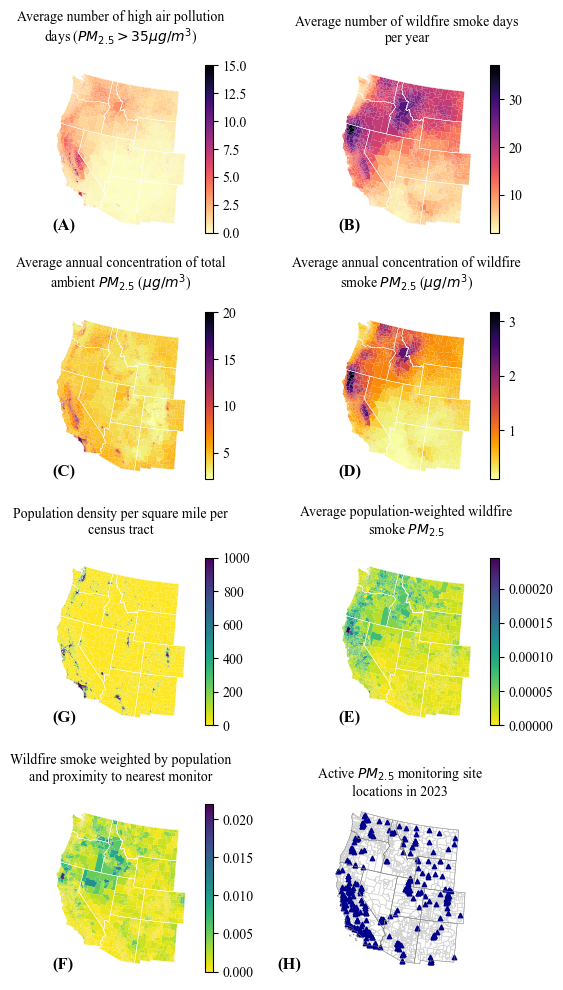

<Figure size 640x480 with 0 Axes>

In [9]:
fig, axes = plt.subplots(4, 2, figsize=(6, 10))

draw_A(axes[0, 0])
#draw_B(axes[0, 1])
draw_C(axes[0, 1])
draw_D(axes[1, 0])
draw_E(axes[1, 1])


draw_popw(axes[2, 1], "(E)")
draw_popdistw(axes[3, 0], "(F)")

draw_population(axes[2, 0], "(G)")
MonitorsDataset().plotMonitors(ax=axes[3, 1], annotation="(H)")
plt.tight_layout()
plt.show()

In [13]:
gdf["POPULATION"] = gdf["POPULATION"].fillna(0).astype(int)

In [15]:
gdf['wg_exp_d'] = gdf['wg_exp_d'].round(3)

In [16]:
gdf.sort_values("wg_exp_d", ascending=False)[["classification","STATE_ABBR","POPULATION","wg_exp_d"]].head(10)

,classification,STATE_ABBR,POPULATION,wg_exp_d
location_label,,,,
16083000701,Urban,ID,11083,0.022
06105000500,Rural,CA,7007,0.019
16013960201,Urban,ID,6226,0.016
16083001301,Urban,ID,7292,0.014
16069960700,Urban,ID,5776,0.014
32007950701,Urban,NV,6886,0.014
16083000200,Urban,ID,7519,0.014
16049960202,Rural,ID,4724,0.014
16083000500,Rural,ID,6587,0.013


In [11]:
temp = gpd.read_file("../coexposure/data/WesternUSCensusTract/CensusTract2020_WesternUS.shp")

In [12]:
temp["county_fips"] = temp["FIPS"].str[0:5]

In [13]:
temp.county_fips.nunique()

415